# FAKE NEWS CLASSIFIER

In [2]:
import kagglehub
path = kagglehub.dataset_download("saurabhshahane/fake-news-classification")

Using Colab cache for faster access to the 'fake-news-classification' dataset.


In [3]:
import os
os.listdir(path)

['WELFake_Dataset.csv']

In [4]:
import pandas as pd
df=pd.read_csv(path+'/WELFake_Dataset.csv')

In [5]:
df.head()

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [6]:
df.shape

(72134, 4)

In [7]:
df.isnull().sum()

,0
Unnamed: 0,0
title,558
text,39
label,0


In [8]:
for col in df.columns:
  print(f'Column {col} has {df[col].isnull().mean()*100:.2f}% of missing values')

Column Unnamed: 0 has 0.00% of missing values
Column title has 0.77% of missing values
Column text has 0.05% of missing values
Column label has 0.00% of missing values


## Since total missing values are very less as compared to total documents so we can remove them

In [9]:
df.dropna(inplace=True)

In [10]:
df.duplicated().sum()

np.int64(0)

## There are no duplicate documents present

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 71537 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  71537 non-null  int64 
 1   title       71537 non-null  object
 2   text        71537 non-null  object
 3   label       71537 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.7+ MB


In [12]:
df['label'].value_counts()

,count
label,
1,36509
0,35028


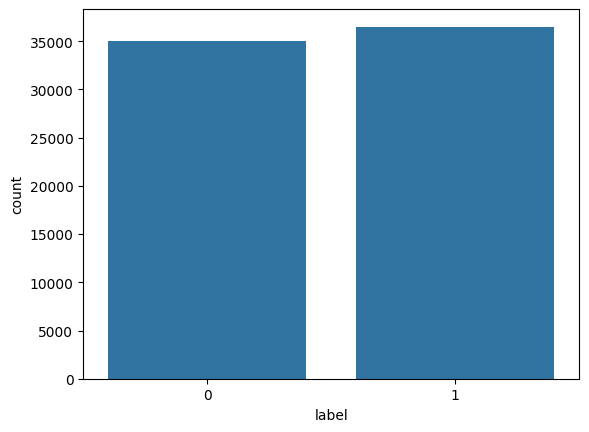

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(df,x='label')
plt.show()

## The data is uniformly distributed!

In [14]:
df['Unnamed: 0'].is_unique

True

In [15]:
df['text'][0]

'No comment is expected from Barack Obama Members of the #FYF911 or #FukYoFlag and #BlackLivesMatter movements called for the lynching and hanging of white people and cops. They encouraged others on a radio show Tuesday night to  turn the tide  and kill white people and cops to send a message about the killing of black people in America.One of the F***YoFlag organizers is called  Sunshine.  She has a radio blog show hosted from Texas called,  Sunshine s F***ing Opinion Radio Show. A snapshot of her #FYF911 @LOLatWhiteFear Twitter page at 9:53 p.m. shows that she was urging supporters to  Call now!! #fyf911 tonight we continue to dismantle the illusion of white Below is a SNAPSHOT Twitter Radio Call Invite   #FYF911The radio show aired at 10:00 p.m. eastern standard time.During the show, callers clearly call for  lynching  and  killing  of white people.A 2:39 minute clip from the radio show can be heard here. It was provided to Breitbart Texas by someone who would like to be referred to

In [16]:
df['title'][0]

'LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops And Whites On 9-11By #BlackLivesMatter And #FYF911 Terrorists [VIDEO]'

In [17]:
df.reset_index(drop=True,inplace=True)

In [18]:
df.head(5)

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
2,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
3,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1
4,5,About Time! Christian Group Sues Amazon and SP...,All we can say on this one is it s about time ...,1


In [19]:
df['text']=df['text'].apply(lambda x: x.lower())
df['title']=df['title'].apply(lambda x: x.lower())

In [20]:
import re
def cleaner(col):
  col=re.sub('<.*?>','',col)
  col=re.sub('https?://\S+|www\.\S+','',col)
  return re.sub('[^\w\s]','',col)
df['title']=df['title'].apply(cleaner)
df['text']=df['text'].apply(cleaner)

<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:5: SyntaxWarning: invalid escape sequence '\w'
<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:5: SyntaxWarning: invalid escape sequence '\w'
/tmp/ipykernel_1537/3937107177.py:4: SyntaxWarning: invalid escape sequence '\S'
  col=re.sub('https?://\S+|www\.\S+','',col)
/tmp/ipykernel_1537/3937107177.py:5: SyntaxWarning: invalid escape sequence '\w'
  return re.sub('[^\w\s]','',col)


In [21]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [22]:
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize,wordpunct_tokenize
words=stopwords.words('english')

In [23]:
def stopword_removal(col):
  L=[]
  tokens=wordpunct_tokenize(col)
  for word in tokens:
    if word not in words:
      L.append(word)
  return " ".join(L)
df['text']=df['text'].apply(stopword_removal)
df['title']=df['title'].apply(stopword_removal)

In [24]:
df['Content']=df['title']+df['text']

In [25]:
df.sample()

,Unnamed: 0,title,text,label,Content
44017,44343,nz rules resettlement manus refugees without a...,wellingtonsydney reuters new zealand resettle ...,0,nz rules resettlement manus refugees without a...


In [26]:
df.drop(columns=['title','text'],inplace=True)

## Separate input and output

In [27]:
x=df['Content']
y=df['label']

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf=TfidfVectorizer()
x=tfidf.fit_transform(x)

In [29]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print(x_train.shape,y_train.shape)

(57229, 419102) (57229,)


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import BernoulliNB

In [31]:
models={
    'LogisticRegressor':LogisticRegression(),
    'BernoulliNB':BernoulliNB()
}
scores={}
for i in range(len(list(models))):
  model=list(models.values())[i]
  model.fit(x_train,y_train)
  y_train_pred=model.predict(x_train)
  y_test_pred=model.predict(x_test)
  scores[list(models)[i]]=accuracy_score(y_train,y_train_pred)
  print(f'For {list(models)[i]} :')
  print(classification_report(y_train,y_train_pred),'\n')
  print(classification_report(y_test,y_test_pred),'\n\n')

For LogisticRegressor :
              precision    recall  f1-score   support

           0       0.97      0.96      0.97     27947
           1       0.96      0.97      0.97     29282

    accuracy                           0.97     57229
   macro avg       0.97      0.97      0.97     57229
weighted avg       0.97      0.97      0.97     57229
 

              precision    recall  f1-score   support

           0       0.96      0.94      0.95      7081
           1       0.94      0.96      0.95      7227

    accuracy                           0.95     14308
   macro avg       0.95      0.95      0.95     14308
weighted avg       0.95      0.95      0.95     14308
 


For BernoulliNB :
              precision    recall  f1-score   support

           0       0.92      0.85      0.88     27947
           1       0.86      0.93      0.90     29282

    accuracy                           0.89     57229
   macro avg       0.89      0.89      0.89     57229
weighted avg       0.89    

In [32]:
scores

{'LogisticRegressor': 0.9670971011200615, 'BernoulliNB': 0.8911216341365392}

In [33]:
model=LogisticRegression()
model.fit(x_train,y_train)
train_pred=model.predict(x_train)
test_pred=model.predict(x_test)

In [34]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_train,train_pred)
print(cm)

[[26815  1132]
 [  751 28531]]


In [39]:
cm=confusion_matrix(y_test,test_pred)
print(cm)

[[6665  416]
 [ 275 6952]]


In [42]:
test=df.sample()
input=tfidf.transform(test['Content'])
print(test)
print(f"The prediction for test data point is {model.predict(input)[0]}")

       Unnamed: 0  label                                            Content
58291       58775      0  ann coulter every time try mad trump media pul...
The prediction for test data point is 0


In [57]:
from sklearn.pipeline import Pipeline
prediction_pipeline=Pipeline(steps=[
    ('tranform',tfidf),
    ('model',model)
])

In [61]:
def predict(text):
  text=cleaner(text)
  text=stopword_removal(text)
  return prediction_pipeline.predict([text])[0]

In [67]:
predict('Launching ATLAS | 1 BHK ₹38.90L* | 2 BHK ₹53.75L')

np.int64(1)

In [63]:
# Let's test both classes to confirm the pipeline predicts 0 and 1 correctly now!
test_real = "President signs new bilateral trade agreement with neighboring countries to boost economy"
test_fake = "Satanic cult controls major global networks and operates underground bases"

print(f"Prediction for Real statement: {predict(test_real)}")
print(f"Prediction for Fake statement: {predict(test_fake)}")

Prediction for Real statement: 0
Prediction for Fake statement: 1
